  Iterazioni   : 282
  Durata reale : 59.98 s
  dt medio     : 213.5 ms
  Errore RMS   : 0.0061 cm
  Errore max   : 0.0135 cm
  RMS q1       : 1.404 deg
  RMS q2       : 6.527 deg
  RMS q3       : 0.543 deg
  RMS q4       : 1.014 deg


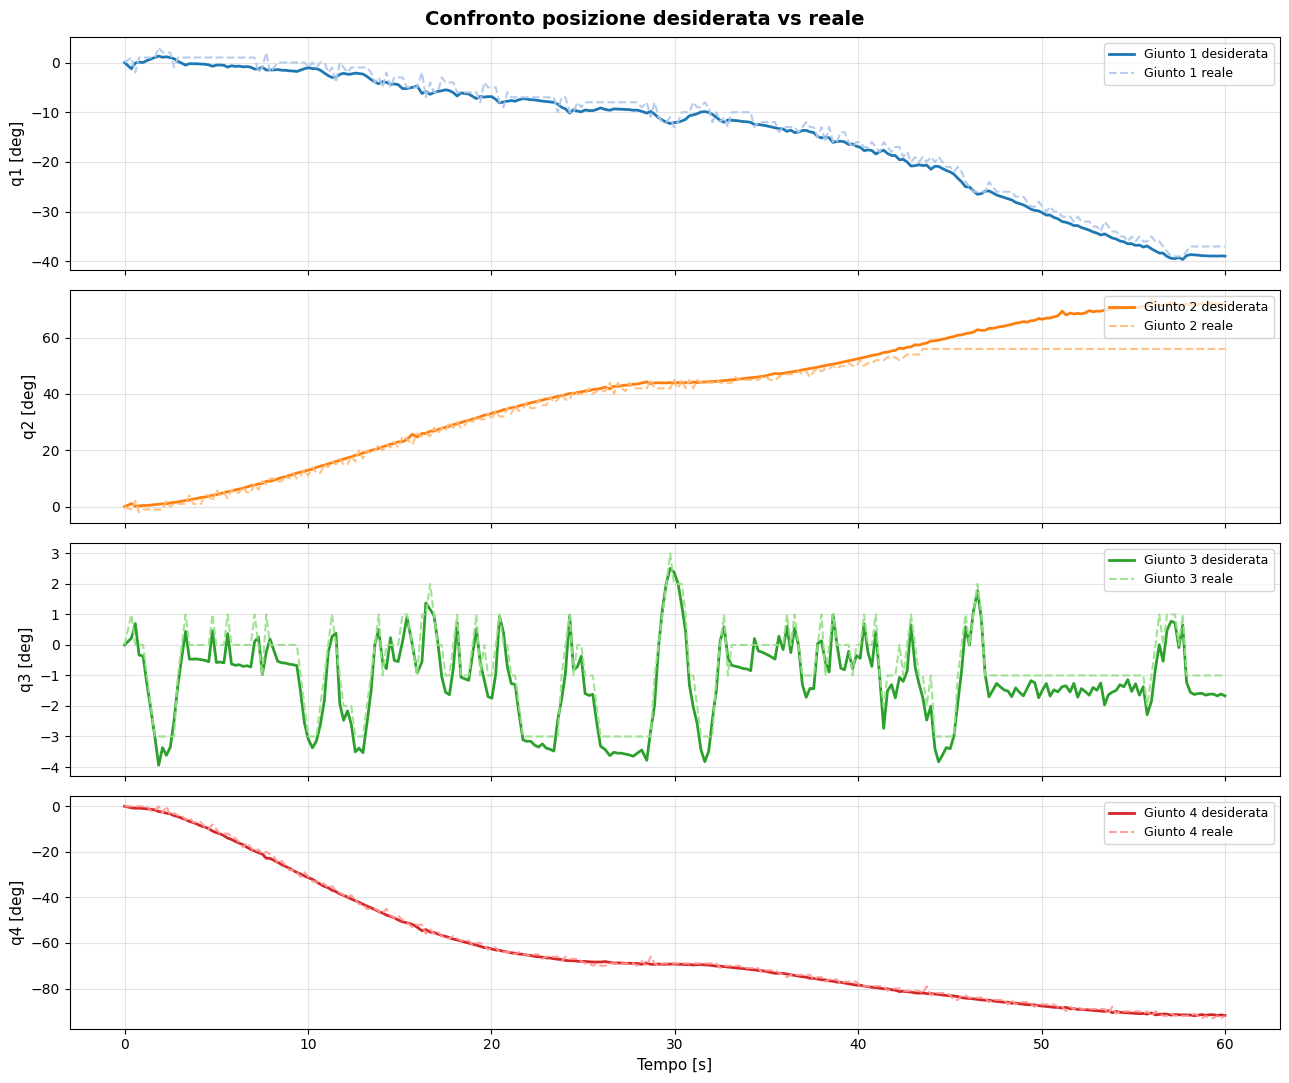

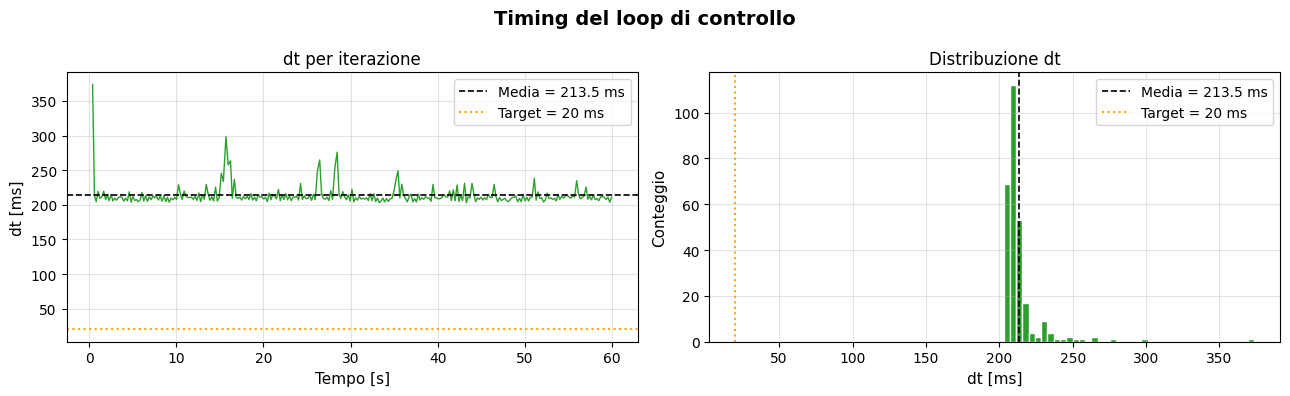

Fatto.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os
import sys

FILE = "confronto_giunti3.txt"
if not os.path.exists(FILE):
    print("File '{}' non trovato. Mettilo nella stessa cartella di questo script.".format(FILE))
    sys.exit(1)

data = np.loadtxt(FILE, delimiter=";", skiprows=1)

tempo   = data[:, 1]
q_des   = [data[:,2], data[:,4], data[:,6], data[:,8]]
q_real  = [data[:,3], data[:,5], data[:,7], data[:,9]]
errore  = data[:,10]

colors_des  = ['#1f77b4','#ff7f0e','#2ca02c','#d62728']
colors_real = ['#aec7e8','#ffbb78','#98df8a','#ff9896']
nomi_giunti = ['Giunto 1','Giunto 2','Giunto 3','Giunto 4']

n_iter  = len(tempo)
dur     = tempo[-1] - tempo[0]
dt_med  = np.mean(np.diff(tempo)) * 1000
rms_err = np.sqrt(np.mean(errore**2))
max_err = np.max(errore)
dt_vect = np.diff(tempo) * 1000

print("="*50)
print("  Iterazioni   : {}".format(n_iter))
print("  Durata reale : {:.2f} s".format(dur))
print("  dt medio     : {:.1f} ms".format(dt_med))
print("  Errore RMS   : {:.4f} cm".format(rms_err))
print("  Errore max   : {:.4f} cm".format(max_err))
for i in range(4):
    e = q_des[i] - q_real[i]
    print("  RMS q{}       : {:.3f} deg".format(i+1, np.sqrt(np.mean(e**2))))
print("="*50)

# ════════════════════════════════════════════════════════
# FIGURA 1 — Confronto desiderato vs reale (tutti i giunti)
# ════════════════════════════════════════════════════════
fig1, axes1 = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
fig1.suptitle("Confronto posizione desiderata vs reale", fontsize=14, fontweight='bold')

for i, ax in enumerate(axes1):
    ax.plot(tempo, q_des[i],  color=colors_des[i],  linewidth=2,
            label="{} desiderata".format(nomi_giunti[i]))
    ax.plot(tempo, q_real[i], color=colors_real[i], linewidth=1.5,
            linestyle='--', alpha=0.9, label="{} reale".format(nomi_giunti[i]))
    ax.set_ylabel("q{} [deg]".format(i+1), fontsize=11)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.35)

axes1[-1].set_xlabel("Tempo [s]", fontsize=11)
plt.tight_layout()


# ════════════════════════════════════════════════════════
# FIGURA 2 — Timing del loop
# ════════════════════════════════════════════════════════
fig4, ax4 = plt.subplots(1, 2, figsize=(13, 4))
fig4.suptitle("Timing del loop di controllo", fontsize=14, fontweight='bold')

ax4[0].plot(tempo[1:], dt_vect, color='#2ca02c', linewidth=1)
ax4[0].axhline(np.mean(dt_vect), color='black', linestyle='--', linewidth=1.2,
               label="Media = {:.1f} ms".format(np.mean(dt_vect)))
ax4[0].axhline(20, color='orange', linestyle=':', linewidth=1.5,
               label="Target = 20 ms")
ax4[0].set_xlabel("Tempo [s]", fontsize=11)
ax4[0].set_ylabel("dt [ms]", fontsize=11)
ax4[0].set_title("dt per iterazione", fontsize=12)
ax4[0].legend(fontsize=10)
ax4[0].grid(True, alpha=0.35)

ax4[1].hist(dt_vect, bins=40, color='#2ca02c', edgecolor='white')
ax4[1].axvline(np.mean(dt_vect), color='black', linestyle='--', linewidth=1.2,
               label="Media = {:.1f} ms".format(np.mean(dt_vect)))
ax4[1].axvline(20, color='orange', linestyle=':', linewidth=1.5,
               label="Target = 20 ms")
ax4[1].set_xlabel("dt [ms]", fontsize=11)
ax4[1].set_ylabel("Conteggio", fontsize=11)
ax4[1].set_title("Distribuzione dt", fontsize=12)
ax4[1].legend(fontsize=10)
ax4[1].grid(True, alpha=0.35)
plt.tight_layout()

plt.show()
print("Fatto.")

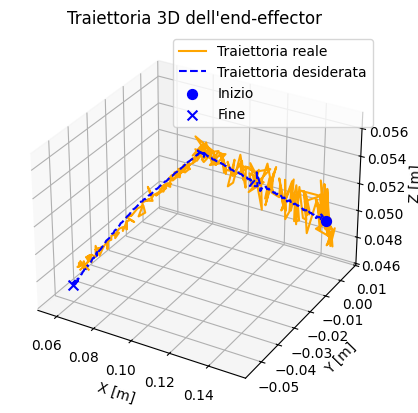

In [8]:
# === ANGOLI DESIDERATI, DA GRADI A RADIANTI ===
q1_des = np.radians(data[:, 2])   # q1_des
q2_des = np.radians(data[:, 4])   # q2_des
q3_des = np.radians(data[:, 6])   # q3_des
q4_des = np.radians(data[:, 8])   # q4_des

Q_des = np.column_stack([q1_des, q2_des, q3_des, q4_des])

# === CALCOLO POSIZIONE EE DESIDERATA ===
P_des = np.array([cinematica_diretta(q) for q in Q_des])

x_des = P_des[:, 0]
y_des = P_des[:, 1]
z_des = P_des[:, 2]

# === PLOT 3D ===
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot(x,     y,     z,     color='orange', label="Traiettoria reale")
ax.plot(x_des, y_des, z_des, color='blue',   linestyle='--', label="Traiettoria desiderata")

ax.scatter(x[0],     y[0],     z[0],     marker="o", color='orange', s=50)
ax.scatter(x_des[0], y_des[0], z_des[0], marker="o", color='blue',   s=50, label="Inizio")
ax.scatter(x[-1],    y[-1],    z[-1],    marker="x", color='orange', s=50)
ax.scatter(x_des[-1],y_des[-1],z_des[-1],marker="x", color='blue',   s=50, label="Fine")

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.set_title("Traiettoria 3D dell'end-effector")
ax.legend()
ax.grid(True)

plt.show()